# MROOT experiment review

This notebook reads saved run histories and comparison tables. It does not train
models, rerun inference, or evaluate the holdout. The complete earlier experiment
history, including failures and approximate historical results, is in
`docs/experiments.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REPORTS = ROOT / "reports/raw"
plt.style.use("default")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

control epochs: 15 best epoch: 7 normal validation mAP: 0.948053
MixUp/CutMix epochs: 19 best epoch: 11 normal validation mAP: 0.960699


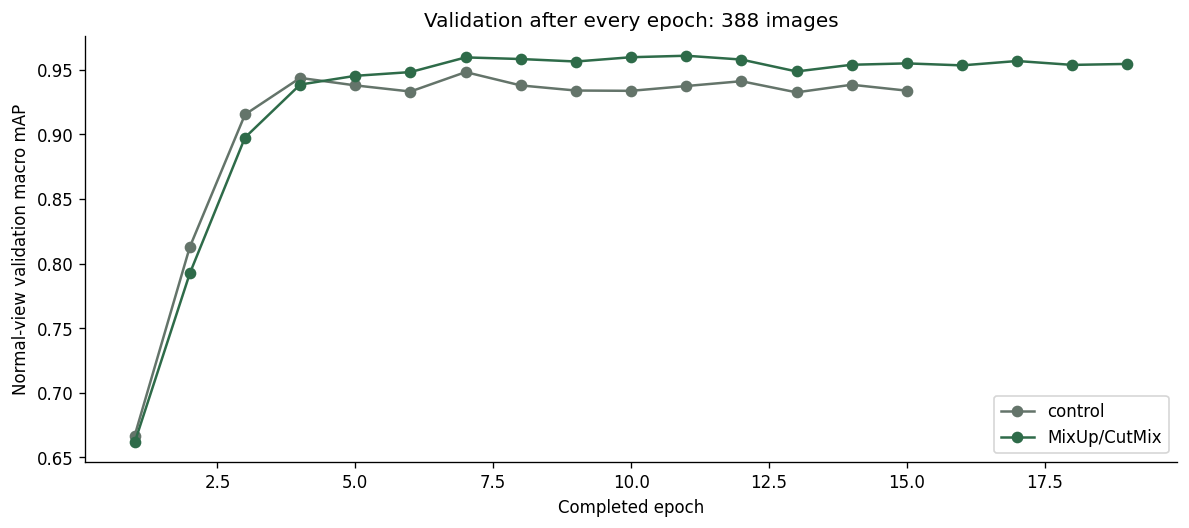

In [2]:
control = pd.read_csv(REPORTS / "control/training_history.csv")
mixed = pd.read_csv(REPORTS / "mixup_cutmix/training_history.csv")
for name, history in [("control", control), ("MixUp/CutMix", mixed)]:
    best = history.loc[history.val_macro_map.idxmax()]
    print(name, "epochs:", len(history), "best epoch:", int(best.epoch), "normal validation mAP:", round(best.val_macro_map, 6))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(control.epoch, control.val_macro_map, "o-", label="control", color="#64746A")
ax.plot(mixed.epoch, mixed.val_macro_map, "o-", label="MixUp/CutMix", color="#2E6B49")
ax.set(xlabel="Completed epoch", ylabel="Normal-view validation macro mAP", title="Validation after every epoch: 388 images")
ax.legend()
fig.tight_layout()

## Matched comparison

The control selected epoch 7 and the mixed run selected epoch 11. They shared
the starting weights and all other recorded settings. I tested a combined
MixUp/CutMix policy, so this comparison cannot tell me which of those two
augmentations helped individually. The reported best epochs come from the
normal-view metric, not from selecting the best ensemble epoch.

In [3]:
comparison = json.loads((REPORTS / "COMPLETED_COMPARISON.json").read_text())
models = pd.DataFrame(comparison["model_comparison"])
print(models[["model", "view", "best_epoch", "images", "macro_map", "top1", "top5"]].round(6).to_string(index=False))
systems = pd.DataFrame(comparison["ensemble_comparison"])
print("\nSame 368-image validation subset:")
print(systems[["system", "models", "images", "macro_map", "top1"]].round(6).to_string(index=False))

       model   view  best_epoch  images  macro_map     top1     top5
     control normal           7     388   0.948053 0.907216 0.994845
     control  fixed           7     388   0.949691 0.907216 0.994845
mixup_cutmix normal          11     388   0.960699 0.925258 0.994845
mixup_cutmix  fixed          11     388   0.960542 0.920103 0.997423

Same 368-image validation subset:
                               system  models  images  macro_map     top1
        Existing four-model reference       4     368   0.954285 0.913043
Same four members, clean control Base       4     368   0.954302 0.913043
 Same four members, MixUp/CutMix Base       4     368   0.959897 0.913043
                   Control Base alone       1     368   0.950930 0.907609
              MixUp/CutMix Base alone       1     368   0.960308 0.918478
         MixUp/CutMix + clean control       2     368   0.964825 0.913043
          MixUp/CutMix + earlier Base       2     368   0.961754 0.910326
           MixUp/CutMix + ne

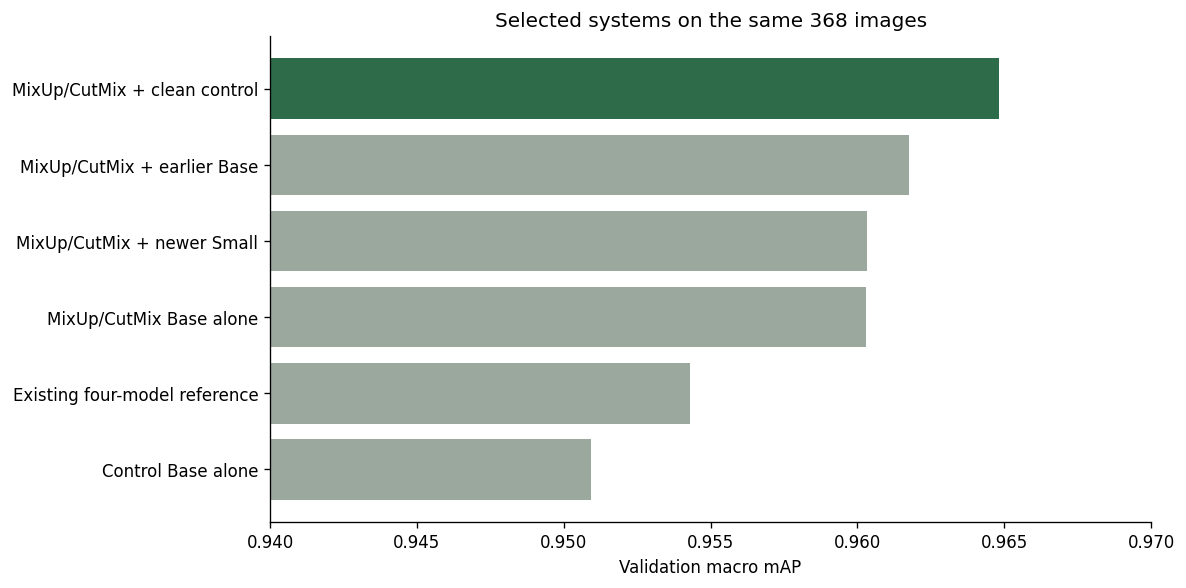

In [4]:
selected = systems[systems.system.isin([
    "Existing four-model reference", "Control Base alone", "MixUp/CutMix Base alone",
    "MixUp/CutMix + clean control", "MixUp/CutMix + earlier Base", "MixUp/CutMix + newer Small",
])].sort_values("macro_map")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(selected.system, selected.macro_map, color=["#2E6B49" if name == "MixUp/CutMix + clean control" else "#9AA89E" for name in selected.system])
ax.set(xlim=(0.94, 0.97), xlabel="Validation macro mAP", title="Selected systems on the same 368 images")
fig.tight_layout()

## What the uncertainty allows me to say

The final pair had the highest observed macro mAP in the checked set. The mixed
model alone with normal inference had higher Top-1 on this subset. I kept macro
mAP as the predefined primary metric. The bootstrap intervals include zero and
do not include every source of model-selection uncertainty.

In [5]:
intervals = comparison["intervals"]
for name, values in intervals.items():
    print(name, "95% interval:", [round(values[0], 6), round(values[-1], 6)])

normal_candidate_minus_control_388 95% interval: [-0.000704, 0.025384]
fixed_candidate_minus_control_388 95% interval: [-0.000757, 0.022804]
ensemble_candidate_minus_control_368 95% interval: [-0.003284, 0.013731]
ensemble_candidate_minus_existing_368 95% interval: [-0.003235, 0.014277]
MixUp/CutMix + clean control minus mixed Base alone, 368 95% interval: [-0.002723, 0.012335]
MixUp/CutMix + earlier Base minus mixed Base alone, 368 95% interval: [-0.005177, 0.009655]
MixUp/CutMix + newer Small minus mixed Base alone, 368 95% interval: [-0.009513, 0.009935]


## Final saved holdout report

The model choice and inference recipe were frozen before this final report.
The 623-image subset had already been evaluated with an earlier system, so this
is not a new untouched-test estimate. Reading this JSON does not reevaluate any
images. I did not use this notebook to choose another experiment.

In [6]:
result = json.loads((REPORTS / "FINAL_HOLDOUT_20261024T103253_167194Z/FINAL_HOLDOUT_RESULT.json").read_text())
print(json.dumps(result, indent=2))

{
  "system": "Equal-weight clean control epoch 7 + MixUp/CutMix epoch 11, fixed TTA",
  "score": {
    "macro_map": 0.9298959361235196,
    "top1": 0.8940609951845907,
    "top5": 0.9935794542536116,
    "images": 623
  },
  "correct_top1": 557,
  "correct_top5": 619,
  "inference_seconds": 71.71444998100196,
  "selection_frozen_before_holdout_read": true,
  "same_previously_frozen_623_images": true,
  "evaluated_other_47_images": false,
  "post_holdout_tuning": false,
  "training_finished": true,
  "original_deployment_changed": false,
  "historical_context": "This holdout was evaluated earlier with a different frozen system. It is not a first-ever untouched-test result."
}
